In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from keras.src.metrics.metrics_utils import confusion_matrix

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [6]:
df = pd.read_csv('/home/kinkini/Downloads/dataset/Lesson_03_Supervised_Learning_ Regression_and_its_Application/Hitters.csv')

df.head()

,Unnamed: 0,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,...,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,-Andy Allanson,293,66,1,30,29,14,1,293,66,...,30,29,14,A,E,446,33,20,NaN,A
1,-Alan Ashby,315,81,7,24,38,39,14,3449,835,...,321,414,375,N,W,632,43,10,475.0,N
2,-Alvin Davis,479,130,18,66,72,76,3,1624,457,...,224,266,263,A,W,880,82,14,480.0,A
3,-Andre Dawson,496,141,20,65,78,37,11,5628,1575,...,828,838,354,N,E,200,11,3,500.0,N
4,-Andres Galarraga,321,87,10,39,42,30,2,396,101,...,48,46,33,N,E,805,40,4,91.5,N


In [10]:
df.columns.tolist()

['Unnamed: 0',
 'AtBat',
 'Hits',
 'HmRun',
 'Runs',
 'RBI',
 'Walks',
 'Years',
 'CAtBat',
 'CHits',
 'CHmRun',
 'CRuns',
 'CRBI',
 'CWalks',
 'League',
 'Division',
 'PutOuts',
 'Assists',
 'Errors',
 'Salary',
 'NewLeague']

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 21 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  322 non-null    str    
 1   AtBat       322 non-null    int64  
 2   Hits        322 non-null    int64  
 3   HmRun       322 non-null    int64  
 4   Runs        322 non-null    int64  
 5   RBI         322 non-null    int64  
 6   Walks       322 non-null    int64  
 7   Years       322 non-null    int64  
 8   CAtBat      322 non-null    int64  
 9   CHits       322 non-null    int64  
 10  CHmRun      322 non-null    int64  
 11  CRuns       322 non-null    int64  
 12  CRBI        322 non-null    int64  
 13  CWalks      322 non-null    int64  
 14  League      322 non-null    str    
 15  Division    322 non-null    str    
 16  PutOuts     322 non-null    int64  
 17  Assists     322 non-null    int64  
 18  Errors      322 non-null    int64  
 19  Salary      263 non-null    float64
 20 

In [9]:
df.isnull().sum()

Unnamed: 0     0
AtBat          0
Hits           0
HmRun          0
Runs           0
RBI            0
Walks          0
Years          0
CAtBat         0
CHits          0
CHmRun         0
CRuns          0
CRBI           0
CWalks         0
League         0
Division       0
PutOuts        0
Assists        0
Errors         0
Salary        59
NewLeague      0
dtype: int64

In [11]:
df = df.dropna(subset=["Salary"])

In [12]:
print(df)

            Unnamed: 0  AtBat  Hits  HmRun  Runs  RBI  Walks  Years  CAtBat  \
1          -Alan Ashby    315    81      7    24   38     39     14    3449   
2         -Alvin Davis    479   130     18    66   72     76      3    1624   
3        -Andre Dawson    496   141     20    65   78     37     11    5628   
4    -Andres Galarraga    321    87     10    39   42     30      2     396   
5     -Alfredo Griffin    594   169      4    74   51     35     11    4408   
..                 ...    ...   ...    ...   ...  ...    ...    ...     ...   
317      -Willie McGee    497   127      7    65   48     37      5    2703   
318   -Willie Randolph    492   136      5    76   50     94     12    5511   
319    -Wayne Tolleson    475   126      3    61   43     52      6    1700   
320     -Willie Upshaw    573   144      9    85   60     78      8    3198   
321     -Willie Wilson    631   170      9    77   44     31     11    4908   

     CHits  ...  CRuns  CRBI  CWalks  League Divisi

In [14]:
median_salary = df["Salary"].median()
print(median_salary)

425.0


In [17]:
df["HighSalary"] = np.where(
    df["Salary"] >= median_salary,
    1,
    0
)
print("Median Salary: ", median_salary)
print(df["HighSalary"].value_counts())

Median Salary:  425.0
HighSalary
1    132
0    131
Name: count, dtype: int64


In [18]:
x = df.drop(
    columns=["Unnamed: 0", "Salary", "HighSalary"]
)
y = df["HighSalary"]

In [19]:
num_cols = x.select_dtypes(
    include = ["number"]
).columns

print(num_cols)

Index(['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 'CAtBat',
       'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'PutOuts', 'Assists',
       'Errors'],
      dtype='str')


In [24]:
cat_cols = x.select_dtypes(
    exclude = ["number"]
).columns

print(cat_cols)

Index(['League', 'Division', 'NewLeague'], dtype='str')


In [26]:
preprocessor = ColumnTransformer(
    transformers= [
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            num_cols
        ),

        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            cat_cols
        )
    ]
)

In [28]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,test_size=0.2,
    random_state=42,
    stratify=y
)

print(x_train.shape)
print(x_test.shape)

(210, 19)
(53, 19)


In [29]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000
    ))
])

In [30]:
model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['AtBat','Hits','HmRun',...,'Assists','Errors','NewLeague']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaini

In [32]:
y_pred = model.predict(x_test)
y_prob = model.predict_proba(x_test)[:,1]
print(y_pred)
print(y_prob)

[0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 1 0 1 1 1 1 0 0 0 0 1 0 1 0 0 1 0 0 0 0 1 1
 0 0 1 1 1 1 1 0 0 1 1 0 0 1 1 0]
[0.09986971 0.23939582 0.06985187 0.62653969 0.54208289 0.81300967
 0.13199733 0.04609527 0.07537839 0.16612119 0.07240131 0.06893916
 0.04403237 0.41473062 0.45320269 0.90726494 0.20227223 0.74135946
 0.99931825 0.98820182 0.98383495 0.19226138 0.13440292 0.02081946
 0.32069477 0.8040104  0.16504269 0.54143321 0.30618908 0.25289879
 0.94365212 0.27346328 0.2272895  0.44785307 0.40265664 0.83051934
 0.99859862 0.34460702 0.476416   0.72055216 0.69293809 0.96587799
 0.94896043 0.97788281 0.04726299 0.23294905 0.55622401 0.88401551
 0.09169538 0.22427158 0.68216948 0.60501978 0.27039985]


In [33]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: ", accuracy)
print("\nClassification Report:")
print(classification_report(y_test,y_pred))
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test,y_pred)
print(cm)

Accuracy:  0.7169811320754716

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.81      0.74        26
           1       0.77      0.63      0.69        27

    accuracy                           0.72        53
   macro avg       0.73      0.72      0.72        53
weighted avg       0.73      0.72      0.71        53


Confusion Matrix:
[[21  5]
 [10 17]]


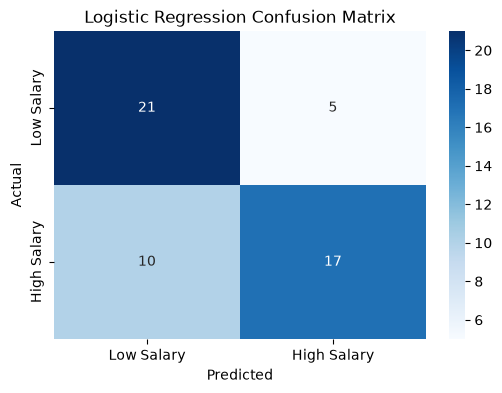

In [34]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Salary", "High Salary"],
    yticklabels=["Low Salary", "High Salary"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [35]:
roc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc)

ROC-AUC Score: 0.8205128205128205


In [36]:
unseen_data = pd.DataFrame({
    "AtBat": [450, 520, 300, 600, 380],
    "Hits": [120, 160, 75, 190, 95],
    "HmRun": [15, 30, 5, 40, 10],
    "Runs": [60, 85, 35, 110, 45],
    "RBI": [55, 95, 25, 120, 40],
    "Walks": [40, 65, 20, 80, 30],
    "Years": [5, 10, 2, 12, 4],
    "CAtBat": [2000, 4500, 500, 6000, 1500],
    "CHits": [550, 1300, 120, 1700, 400],
    "CHmRun": [60, 180, 10, 250, 35],
    "CRuns": [250, 700, 50, 900, 180],
    "CRBI": [230, 650, 45, 950, 160],
    "CWalks": [180, 400, 30, 500, 120],
    "League": ["A", "N", "A", "N", "A"],
    "Division": ["E", "W", "W", "E", "E"],
    "PutOuts": [200, 300, 100, 400, 150],
    "Assists": [10, 20, 5, 30, 8],
    "Errors": [5, 8, 2, 4, 6],
    "NewLeague": ["A", "N", "A", "N", "A"]
})

print(unseen_data)

   AtBat  Hits  HmRun  Runs  RBI  Walks  Years  CAtBat  CHits  CHmRun  CRuns  \
0    450   120     15    60   55     40      5    2000    550      60    250   
1    520   160     30    85   95     65     10    4500   1300     180    700   
2    300    75      5    35   25     20      2     500    120      10     50   
3    600   190     40   110  120     80     12    6000   1700     250    900   
4    380    95     10    45   40     30      4    1500    400      35    180   

   CRBI  CWalks League Division  PutOuts  Assists  Errors NewLeague  
0   230     180      A        E      200       10       5         A  
1   650     400      N        W      300       20       8         N  
2    45      30      A        W      100        5       2         A  
3   950     500      N        E      400       30       4         N  
4   160     120      A        E      150        8       6         A  


In [39]:
predictions = model.predict(unseen_data)
probabilities = model.predict_proba(unseen_data)[:, 1]

In [40]:
results = unseen_data.copy()

results["Predicted_Class"] = predictions

results["High_Salary_Probability"] = probabilities

results["Predicted_Salary_Category"] = np.where(
    predictions == 1,
    "High Salary",
    "Low Salary"
)

print(results[[
    "Predicted_Class",
    "High_Salary_Probability",
    "Predicted_Salary_Category"
]])

   Predicted_Class  High_Salary_Probability Predicted_Salary_Category
0                0                 0.330900                Low Salary
1                1                 0.981302               High Salary
2                0                 0.048545                Low Salary
3                1                 0.998443               High Salary
4                0                 0.145174                Low Salary
